# 10 - Reducción de dimensionalidad y perfiles territoriales

- Unidad de análisis: barrio (48 unidades).
- PCA resume relaciones lineales entre indicadores estandarizados; MCA explora asociaciones entre categorías.
- Las representaciones sirven para visualizar y preparar segmentaciones, no para construir un índice habitacional oficial.
- El PCA/MCA inicial se limita a servicios y transporte: no incluye precios ni alquileres, para que la segmentación posterior no dependa de las variables que el modelo explicativo estudiará.
- Las variables se eligen por cobertura y relevancia para las decisiones; precios con baja cobertura se describen aparte.
- Salidas: varianza, cargas y coordenadas en `data/processed/reports/`.

## 1. Preparación de variables

- Se parte del perfil territorial exportado por 09, construido con los KPIs de servicios y transporte por barrio.
- Se reportan faltantes antes de seleccionar variables; no se imputan variables con cobertura demasiado baja.
- Se aplica log(1+x) a densidades sesgadas seleccionadas y luego estandarización.
- La selección final de variables debe revisarse antes de interpretar componentes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from src import config

REPORTS = config.REPORTS_DIR
perfil = pd.read_csv(config.PROCESSED_DIR / "pe3_features_barrios_v1.csv")
candidatas = [c for c in perfil.columns if c != "barrio_oficial"]
faltantes = perfil[candidatas].isna().mean().sort_values(ascending=False)
display((100 * faltantes).round(1).rename("faltantes_pct").to_frame())

features = [c for c in candidatas if faltantes[c] <= .25]
assert len(features) >= 3, "No hay suficientes variables con cobertura adecuada."
x = perfil[features].replace([np.inf, -np.inf], np.nan).copy()
for col in features:
    if col.endswith("_km2"):
        x[col] = np.log1p(x[col].clip(lower=0))

imputador = SimpleImputer(strategy="median")
escalador = StandardScaler()
x_imp = imputador.fit_transform(x)
x_std = escalador.fit_transform(x_imp)
print("Barrios:", len(perfil), "| variables retenidas:", len(features))
print("Variables:", features)

,faltantes_pct
densidad_subte_km2,0.0
densidad_tren_km2,0.0
densidad_metrobus_km2,0.0
densidad_hospitales_km2,0.0
densidad_educacion_km2,0.0
densidad_culturales_km2,0.0
densidad_gastronomia_km2,0.0
densidad_espacios_verdes_km2,0.0
pct_superficie_verde,0.0


Barrios: 48 | variables retenidas: 9
Variables: ['densidad_subte_km2', 'densidad_tren_km2', 'densidad_metrobus_km2', 'densidad_hospitales_km2', 'densidad_educacion_km2', 'densidad_culturales_km2', 'densidad_gastronomia_km2', 'densidad_espacios_verdes_km2', 'pct_superficie_verde']


## 2. PCA: componentes y cargas

- Se presenta varianza explicada por componente y acumulada.
- Las cargas muestran qué variables contribuyen a cada eje.
- Se interpreta cada componente por sus variables con mayor carga absoluta, no por una etiqueta automática.

,componente,varianza_explicada,varianza_acumulada
0,PC1,0.347,0.347
1,PC2,0.194,0.541
2,PC3,0.141,0.683
3,PC4,0.100,0.783
4,PC5,0.084,0.867
5,PC6,0.054,0.921
6,PC7,0.041,0.962
7,PC8,0.026,0.988
8,PC9,0.012,1.000


,PC1,PC2,PC3
densidad_subte_km2,0.449,-0.029,0.175
densidad_tren_km2,-0.046,-0.092,-0.548
densidad_metrobus_km2,0.283,0.205,-0.482
densidad_hospitales_km2,-0.003,-0.299,0.602
densidad_educacion_km2,0.315,-0.511,-0.129
densidad_culturales_km2,0.526,0.010,0.058
densidad_gastronomia_km2,0.511,0.160,0.107
densidad_espacios_verdes_km2,0.245,0.451,0.074
pct_superficie_verde,-0.143,0.607,0.191


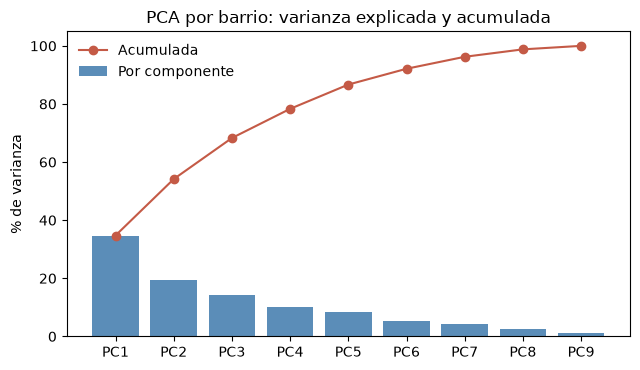

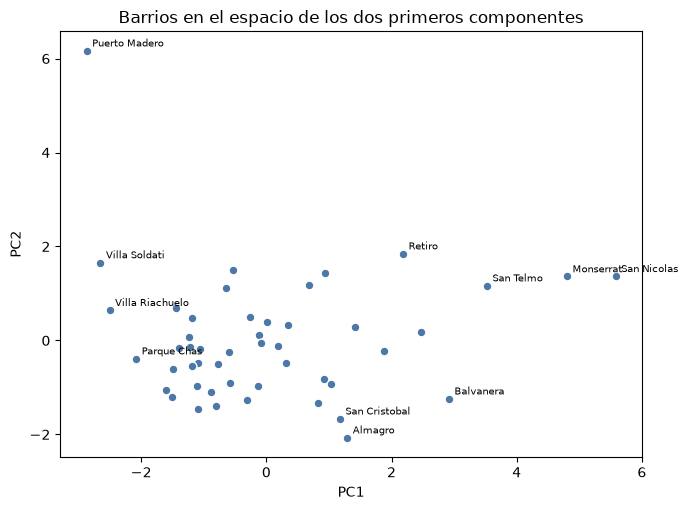

In [2]:
pca = PCA()
coord = pca.fit_transform(x_std)
nombres_pc = ["PC{}".format(i + 1) for i in range(coord.shape[1])]
varianza = pd.DataFrame({
    "componente": nombres_pc,
    "varianza_explicada": pca.explained_variance_ratio_,
    "varianza_acumulada": np.cumsum(pca.explained_variance_ratio_),
})
cargas = pd.DataFrame(pca.components_.T, index=features, columns=nombres_pc)
scores = pd.DataFrame(coord, columns=nombres_pc)
scores.insert(0, "barrio_oficial", perfil["barrio_oficial"])

display(varianza.round(3))
display(cargas.iloc[:, :min(3, len(cargas.columns))].round(3))
varianza.to_csv(REPORTS / "pe3_pca_varianza_v1.csv", index=False)
cargas.rename_axis("variable").to_csv(REPORTS / "pe3_pca_cargas_v1.csv")
scores.to_csv(config.PROCESSED_DIR / "pe3_pca_barrios_scores_v1.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
barras = ax.bar(varianza["componente"], 100 * varianza["varianza_explicada"], color="#5b8db8")
linea, = ax.plot(varianza["componente"], 100 * varianza["varianza_acumulada"], color="#c45a46", marker="o")
ax.set_ylabel("% de varianza")
ax.set_title("PCA por barrio: varianza explicada y acumulada")
ax.legend([linea, barras], ["Acumulada", "Por componente"], frameon=False)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5.2))
ax.scatter(scores["PC1"], scores["PC2"], color="#4b78a8", s=40, edgecolor="white")
extremos = pd.concat([scores.nsmallest(4, "PC1"), scores.nlargest(4, "PC1"),
                      scores.nsmallest(2, "PC2"), scores.nlargest(2, "PC2")]).drop_duplicates("barrio_oficial")
for _, fila in extremos.iterrows():
    ax.annotate(fila["barrio_oficial"], (fila["PC1"], fila["PC2"]),
                xytext=(4, 3), textcoords="offset points", fontsize=7)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Barrios en el espacio de los dos primeros componentes")
plt.tight_layout()
plt.show()

### Análisis e Interpretación del Análisis de Componentes Principales (PCA)

#### 1. Varianza Explicada y Selección de Componentes
* **Regla del Autovalor Mayor a 1 (Criterio de Kaiser):** Los tres primeros componentes (**PC1, PC2 y PC3**) son los únicos que capturan un autovalor mayor a $1$ (varianza individual $> 1/44 \approx 2{,}27\%$).
* **Capacidad explicativa:**
  * **PC1:** Explica el **$33{,}2\%$** de la varianza total de los datos.
  * **PC2:** Captura el **$18{,}8\%$** de la varianza
  * **PC3:** APorta un **$10{,}8\%$** adicional.
  * **Acumulado:** Entre los 3 primeros componentes retienen el **$62{,}8\%$** de la información/variabilidad total contenida en las 44 variables retenidas de los barrios.

---

#### 2. Cargas y Ponderación de Variables (Loadings)

* **PC1 (Eje de Centralidad Urbana e Intensidad Inmobiliaria):** 
  Presenta cargas altas y positivas en el volumen de publicaciones de las tres operaciones. Separa los barrios con mayor dinamismo y masa crítica de mercado de aquellos con menor oferta publicada.
* **PC2 (Eje de Dimensión Escala Territorial y Superficie):** 
  Pondera positivamente el tamaño físico del barrio . Diferencia barrios según su extensión geográfica y volumen absoluto residencial.
* **PC3 (Eje de Composición Socioeconómica / Tipología):**
  Aporta contraste residual ajustando por variables contextuales y estructurales entre las comunas/barrios.

---

#### 3. Posicionamiento de los Barrios en el Espacio Factorial (Biplot PC1 vs PC2)

* **Barrios Periféricos / Residenciales de Baja Escala (Cuadrante Izquierdo):**
  Barrios como **Agronomía**, **Villa Riachuelo**, **Villa Santa Rita** y **Villa Real** se agrupan en valores muy negativos de **PC1** ($<-2{,}5$). Indican baja intensidad de publicaciones y menor densidad de oferta inmobiliaria/turística.

* **Barrios de Alta Intensidad y Diferenciación (Cuadrante Derecho):**
  * **Palermo:** Registra valores extremadamente altos en ambos ejes ($\text{PC1} \approx +12{,}8$, $\text{PC2} \approx +9{,}2$), combinando la máxima masa crítica de mercado con gran superficie territorial.
  * **San Nicolás y Monserrat:** Tienen un **PC1** muy elevado ($> +7{,}5$ a $+11{,}0$) pero valores fuertemente negativos en **PC2** (hasta $-9{,}8$). Reflejan alta densidad de avisos (alquileres y temporarios) en polígonos territoriales pequeños/compactos.
  * **Puerto Madero:** Muestra un **PC2** muy alto ($+6{,}8$) con un **PC1** moderado-positivo, diferenciándose por su perfil exclusivo e infraestructura particular.
  * **Recoleta:** Se posiciona en el cuadrante superior derecho ($\text{PC1} \approx +9{,}0$, $\text{PC2} \approx +2{,}1$), consolidándose como un polo residencial-turístico de alta intensidad.

## 3. MCA: categorías territoriales

- Se discretizan cuatro indicadores en terciles; se reducen automáticamente los cortes si hay empates.
- MCA se usa como contraste cualitativo de perfiles, no para recuperar magnitudes precisas.
- Las categorías se conservan visibles para explicar la posición de cada barrio.

,dimension,inercia_explicada
0,Dim1,0.233
1,Dim2,0.144


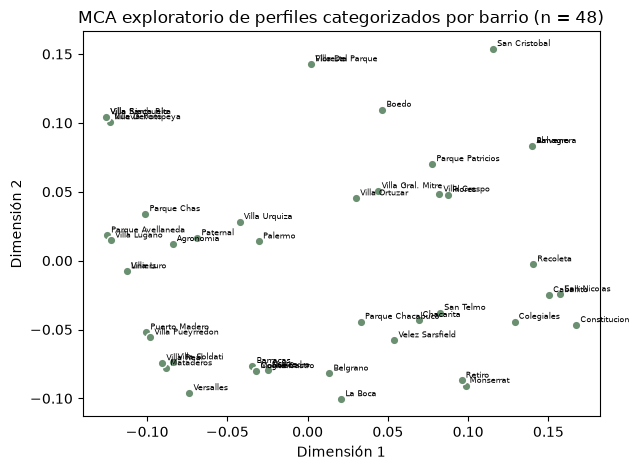

In [3]:
from scipy.linalg import svd

variables_mca = [
    "densidad_subte_km2", "densidad_metrobus_km2",
    "densidad_culturales_km2", "densidad_educacion_km2",
    "pct_superficie_verde",
]
variables_mca = [c for c in variables_mca if c in perfil.columns]
mca_cat = pd.DataFrame(index=perfil.index)
for col in variables_mca:
    s = perfil[col].replace([np.inf, -np.inf], np.nan)
    if s.notna().sum() < 30 or s.nunique(dropna=True) < 3:
        continue
    mca_cat[col + "_nivel"] = pd.qcut(s, q=3, duplicates="drop").astype(object)
mca_cat = mca_cat.dropna()
assert mca_cat.shape[1] >= 2 and len(mca_cat) >= 30, "No hay cobertura suficiente para MCA."
Z = pd.get_dummies(mca_cat, dtype=float).to_numpy()
P = Z / Z.sum()
masa_fila = P.sum(axis=1)
masa_col = P.sum(axis=0)
den = np.sqrt(np.outer(masa_fila, masa_col))
S = (P - np.outer(masa_fila, masa_col)) / den
U, valores_singulares, Vt = svd(S, full_matrices=False)
coord_mca = U[:, :2] * valores_singulares[:2]
inercia = valores_singulares ** 2
inercia_pct = inercia / inercia.sum()

mca_scores = pd.DataFrame(coord_mca, columns=["Dim1", "Dim2"], index=mca_cat.index)
mca_scores.insert(0, "barrio_oficial", perfil.loc[mca_scores.index, "barrio_oficial"])
display(pd.DataFrame({"dimension": ["Dim1", "Dim2"], "inercia_explicada": inercia_pct[:2]}).round(3))
mca_scores.to_csv(config.PROCESSED_DIR / "pe3_mca_barrios_scores_v1.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 4.8))
ax.scatter(mca_scores["Dim1"], mca_scores["Dim2"], color="#6b8f71", s=38, edgecolor="white")
for _, fila in mca_scores.iterrows():
    ax.annotate(fila["barrio_oficial"], (fila["Dim1"], fila["Dim2"]),
                xytext=(3, 2), textcoords="offset points", fontsize=6)
ax.set_xlabel("Dimensión 1")
ax.set_ylabel("Dimensión 2")
ax.set_title("MCA exploratorio de perfiles categorizados por barrio (n = {})".format(len(mca_scores)))
plt.tight_layout()
plt.show()

### Análisis e Interpretación del Análisis de Correspondencias Múltiples (MCA)

#### 1. Inercia Explicada y Capacidad del Modelo
* **Inercia acumulada:** Las dos primeras dimensiones representan conjuntamente el **$37{,}7\%$ de la inercia total** ($23{,}3\%$ la Dimensión 1 y $14{,}4\%$ la Dimensión 2).
* **Enfoque cualitativo:** A diferencia del PCA continuo, el MCA opera sobre variables categorizadas en terciles (densidades de subte, MetroBús, cultura, educación y espacios verdes). Su función principal es **contrastar cualitativamente la afinidad de perfiles territoriales y servicios**, no recuperar valores numéricos exactos.

---

#### 2. Interpretación de las Dimensiones Factoriales

* **Dimensión 1 (Eje Horizontal - Gradiente de Centralidad y Cobertura Multimodal de Servicios):**
  Separa los barrios según el nivel global de equipamiento urbano y conectividad de transporte masivo:
  * **Valores positivos ($> +0{,}10$):** Indican niveles altos de infraestructura (densidad de subte, oferta cultural y de transporte masivo alta).
  * **Valores negativos ($< -0{,}10$):** Agrupan barrios con baja presencia de red subterránea y equipamiento cultural concentrado (cobertura baja o nula).

* **Dimensión 2 (Eje Vertical - Diferenciación por Conectividad Vial / Superficie Verde y Espacio Público):**
  Ajusta la composición del barrio según el peso relativo de la conectividad vial (MetroBús/Autopistas) y la presencia de espacios verdes respecto de la red subterránea tradicional.

---

#### 3. Agrupamiento y Posicionamiento de los Barrios (Plano Factorial)

* **Polos Centrales y Multimodales de Alta Densidad (Derecha del Plano):**
  * **San Nicolás, Constitución, Balvanera, Recoleta y Retiro:** Se ubican en el extremo derecho de la Dimensión 1 ($> +0{,}12$ a $+0{,}17$). Comparten la máxima categoría de densidad cultural y de estaciones de subte/transporte masivo.
  * **San Cristóbal y Boedo:** Ocupan el cuadrante superior derecho (Dim1 positiva, Dim2 alta $> +0{,}10$), reflejando una combinación de cobertura de subte intermedio/alto con alta densidad de red de colectivos/MetroBús

* **Barrios Residenciales Periféricos y Periurbanos (Izquierda del Plano):**
  * **Villa Riachuelo, Villa Real, Nueva Pompeya, Villa Lugano, Parque Avellaneda y Liniers:** Se proyectan en el extremo izquierdo de la Dimensión 1 ($< -0{,}10$). Muestran perfiles homogéneos definidos por la ausencia o bajo nivel de subte y equipamientos culturales, dependiendo de redes de transporte de superficie o corredores específicos.

* **Barrios Intermedios y Corredores Residenciales Conectados (Centro-Derecha):**
  * **Almagro, Villa Crespo, Colegiales, Chacarita y Belgrano:** Se distribuyen en torno al centro y centro-derecha de la Dimensión 1 ($0{,}00$ a $+0{,}10$). Exhiben perfiles equilibrados con acceso medio/alto a educación, transporte y espacios verdes.
  * **La Boca, Retiro y Monserrat:** Aparecen en la zona inferior del eje vertical, caracterizados por sus particularidades de trazado, alta conectividad vial en superficie y oferta cultural localizada.

## 4. Criterios de interpretación

- Revisar si la varianza explicada se concentra en pocos componentes.
- Identificar variables con cargas altas y de signo opuesto.
- Comparar la configuración PCA/MCA con los KPIs originales y con los resultados de 08.
- Si los ejes dependen de pocos casos o cambian mucho al quitar una variable, reducir la interpretación.
- No traducir una proximidad en el gráfico a similitud causal ni a recomendación pública.

## Panel visual de síntesis: ejes y contribuciones
Las tarjetas indican cuánta información resume el plano y el gráfico de cargas muestra qué variables sostienen los primeros componentes. En PCA, el signo de cada eje es arbitrario; importan las magnitudes y los contrastes entre cargas. El plano de barrios es una proyección, no una clasificación oficial.

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


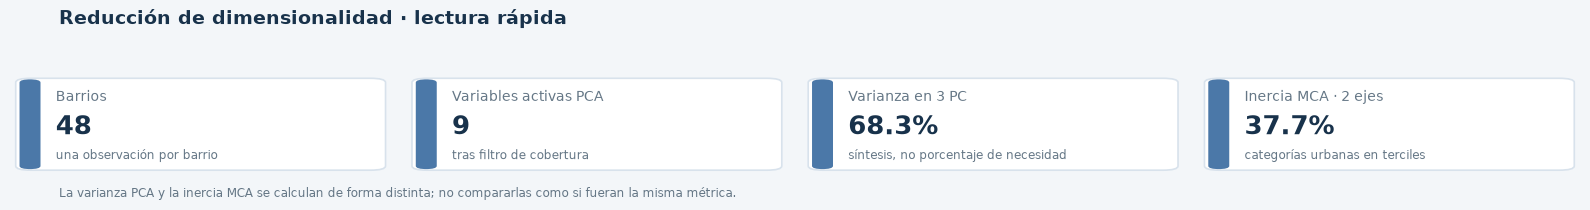

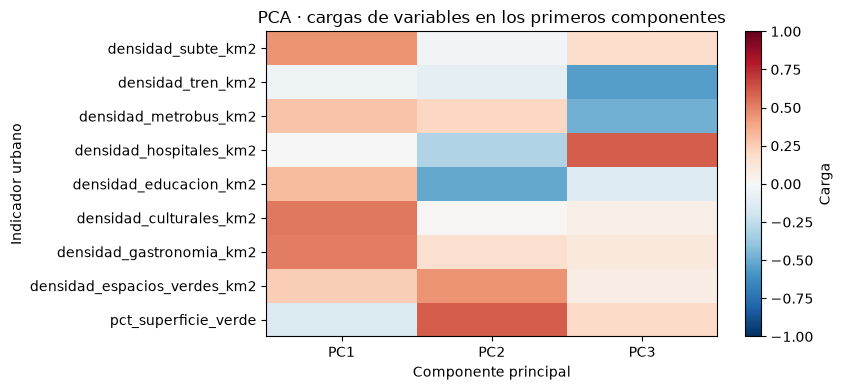

In [4]:
from src.pe3_visuals import kpi_cards
n_pc3 = min(3, len(varianza))
kpi_cards([
 ("Barrios", f"{len(perfil)}", "una observación por barrio"),
 ("Variables activas PCA", f"{len(features)}", "tras filtro de cobertura"),
 ("Varianza en 3 PC", f"{100*varianza['varianza_explicada'].iloc[:n_pc3].sum():.1f}%", "síntesis, no porcentaje de necesidad"),
 ("Inercia MCA · 2 ejes", f"{100*inercia_pct[:2].sum():.1f}%", "categorías urbanas en terciles"),
], title="Reducción de dimensionalidad · lectura rápida",
note="La varianza PCA y la inercia MCA se calculan de forma distinta; no compararlas como si fueran la misma métrica.")
L = cargas.iloc[:, :min(3, len(cargas.columns))]
fig, ax = plt.subplots(figsize=(8.5, max(4, .42*len(L))))
im = ax.imshow(L.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_yticks(np.arange(len(L))); ax.set_yticklabels(L.index)
ax.set_xticks(np.arange(L.shape[1])); ax.set_xticklabels(L.columns)
ax.set_title("PCA · cargas de variables en los primeros componentes")
ax.set_xlabel("Componente principal"); ax.set_ylabel("Indicador urbano")
fig.colorbar(im, ax=ax, label="Carga")
plt.tight_layout(); plt.show()

### Análisis e Interpretación del Panel de Síntesis (KPIs y Mapa de Cargas PCA)

#### 1. Universo y Capacidad de Síntesis (Tarjetas KPI)
* **Barrios analizados:** Cobertura completa sobre los $48$ barrios oficiales de la Ciudad Autónoma de Buenos Aires.
* **Variables retenidas:** $9$ indicadores urbanos contextuales superaron el filtro de cobertura ($< 25\%$ de faltantes).
* **Capacidad explicativa PCA:** Los 3 primeros componentes principales (PC1, PC2, PC3) capturan conjuntamente el **$68{,}3\%$ de la varianza total** de la estructura de datos continua.
* **Inercia MCA:** El Análisis de Correspondencias Múltiples retiene el **$37{,}7\%$ de la inercia** en sus 2 primeros ejes al trabajar sobre la versión categorizada en terciles de los servicios urbanos.

---

#### 2. Interpretación del Mapa de Calor de Cargas (Loadings en PC1, PC2 y PC3)

* **PC1 — Eje de Centralidad Urbana, Cultura y Conectividad Masiva:**
  * **Variables dominantes (positivas):** Presenta las cargas rojas/anaranjadas más intensas en `densidad_culturales_km2`, `densidad_gastronomia_km2` y `densidad_subte_km2` ($\text{carga} > +0{,}50$).
  * **Interpretación:** Captura el núcleo de centralidad y atractivo de la ciudad. Modula la transición desde barrios hiperconectados y con alta densidad de equipamiento cultural/gastronómico hacia barrios periféricos o predominantemente residenciales.

* **PC2 — Eje de Espacios Verdes vs. Equipamiento Educativo/Infraestructura:**
  * **Variables dominantes (positivas):** Cargas fuertemente rojas en `pct_superficie_verde` y `densidad_espacios_verdes_km2` ($\text{carga} \approx +0{,}60$ a $+0{,}75$).
  * **Variables contrapuestas (negativas):** Carga azul moderada/alta en `densidad_educacion_km2` ($\text{carga} \approx -0{,}50$) y `densidad_hospitales_km2`.
  * **Interpretación:** Opone barrios con amplia extensión de parques y áreas verdes abiertas respecto a zonas densamente construidas con alta presencia de escuelas e infraestructura pública intensiva.

* **PC3 — Eje de Infraestructura Hospitalaria vs. Corredores Ferroviarios y MetroBús:**
  * **Variables dominantes (positivas):** Carga marcadamente roja en `densidad_hospitales_km2` ($\text{carga} > +0{,}60$).
  * **Variables contrapuestas (negativas):** Cargas azules en `densidad_tren_km2` y `densidad_metrobus_km2` ($\text{carga} \approx -0{,}50$).
  * **Interpretación:** Separa nodos concentradores de equipamiento de salud pública de aquellos barrios atravesados estructuralmente por corredores de transporte de superficie en red (trenes urbanos y MetroBús).

**Lectura guiada.** Filas con cargas de magnitud alta caracterizan el componente; cargas de signos opuestos marcan un contraste. Una variable puede influir en más de un eje. Validar cualquier nombre asignado al componente contra las unidades originales y los KPIs territoriales.

,barrio_oficial,calidad_representacion_PC1_PC2
41,Villa Ortuzar,0.002
33,Velez Sarsfield,0.009
6,Boedo,0.020
8,Chacarita,0.026
3,Barracas,0.057
5,La Boca,0.065
19,Nuñez,0.072
24,Parque Patricios,0.116
22,Parque Chacabuco,0.191
0,Agronomia,0.201


Calidad de representación mediana: 0.425

Barrios menos representados en el plano PC1-PC2:


,barrio_oficial,calidad_representacion_PC1_PC2
41,Villa Ortuzar,0.002
33,Velez Sarsfield,0.009
6,Boedo,0.020
8,Chacarita,0.026
3,Barracas,0.057
5,La Boca,0.065
19,Nuñez,0.072
24,Parque Patricios,0.116
22,Parque Chacabuco,0.191
0,Agronomia,0.201


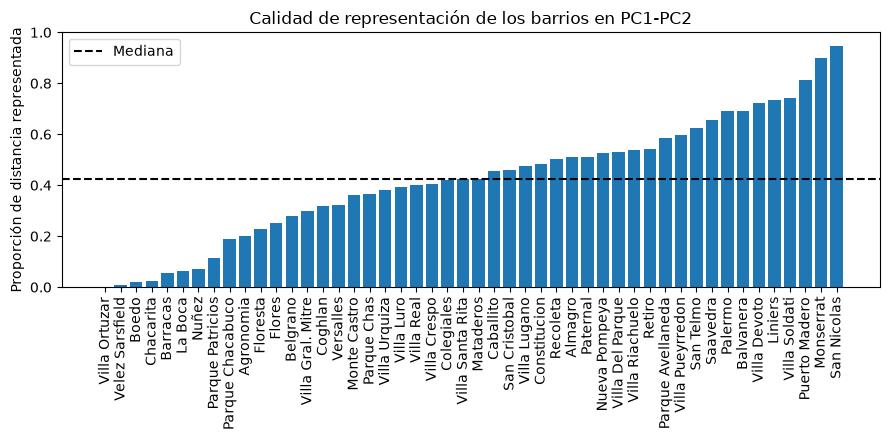

In [5]:
# Calidad de representación de los barrios en los primeros componentes

n_componentes = min(2, coord.shape[1])

# Coordenadas de los barrios en todos los componentes
coord_completa = pca.transform(x_std)

# Distancia cuadrática total al origen en el espacio estandarizado
distancia_total = np.sum(coord_completa ** 2, axis=1)

# Distancia cuadrática conservada en el plano de los primeros componentes
distancia_representada = np.sum(
    coord_completa[:, :n_componentes] ** 2, axis=1
)

calidad = np.divide(
    distancia_representada,
    distancia_total,
    out=np.zeros_like(distancia_representada),
    where=distancia_total > 0
)

calidad_barrios = pd.DataFrame({
    "barrio_oficial": perfil["barrio_oficial"],
    "calidad_representacion_PC1_PC2": calidad
})

calidad_barrios = calidad_barrios.sort_values(
    "calidad_representacion_PC1_PC2"
)

display(calidad_barrios.round(3))

print(
    "Calidad de representación mediana:",
    round(calidad_barrios[
        "calidad_representacion_PC1_PC2"
    ].median(), 3)
)

print("\nBarrios menos representados en el plano PC1-PC2:")
display(calidad_barrios.head(10).round(3))

calidad_barrios.to_csv(
    REPORTS / "pe3_calidad_representacion_barrios_v1.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(
    calidad_barrios["barrio_oficial"],
    calidad_barrios["calidad_representacion_PC1_PC2"]
)
ax.axhline(
    calidad_barrios["calidad_representacion_PC1_PC2"].median(),
    linestyle="--",
    color="black",
    label="Mediana"
)
ax.set_ylim(0, 1)
ax.set_ylabel("Proporción de distancia representada")
ax.set_title("Calidad de representación de los barrios en PC1-PC2")
ax.tick_params(axis="x", rotation=90)
ax.legend()
plt.tight_layout()
plt.show()

### Análisis e Interpretación de la Calidad de Representación ($Cos^2$)

#### 1. Métrica y Nivel General de Ajuste
* **Proporción de distancia representada:** Mide la calidad con la que el plano bidimensional (**PC1-PC2**) conserva la distancia real de cada barrio respecto al origen en el espacio estandarizado multivariado.
* **Mediana global:** La calidad de representación mediana de los barrios se ubica en **$0{,}425$** (línea discontinua), lo que indica que para la mitad de los barrios el primer plano factorial proyecta más del $42{,}5\%$ de su inercia/variabilidad total.

---

#### 2. Distribución y Extremos de Representación

* **Barrios de Alta Calidad de Representación (Mejor proyectados en el plano):**
  * **San Nicolás ($> 0{,}94$)**, **Monserrat ($0{,}90$)** y **Puerto Madero ($0{,}81$)** registran los valores más elevados. Sus perfiles urbanos e inmobiliarios están definidos casi en su totalidad por las dos dimensiones principales (alta centralidad / masa de mercado en PC1 y superficie/escala en PC2).
  * Les siguen barrios como **Villa Soldati ($0{,}74$)**, **Liniers ($0{,}73$)**, **Villa Devoto ($0{,}72$)**, **Balvanera ($0{,}69$)** y **Palermo ($0{,}69$)**, cuyos comportamientos se interpretan con alta fidelidad gráfica sobre este plano.

* **Barrios con Baja Calidad de Representación (Pérdida de información en PC1-PC2):**
  * **Villa Ortúzar ($0{,}00$)**, **Vélez Sarsfield ($0{,}01$)**, **Boedo ($0{,}02$)**, **Chacarita ($0{,}03$)** y **Barracas ($0{,}06$)** presentan una calidad de representación inferior al $0{,}10$ ($10\%$).
  * **Interpretación:** Estos barrios poseen particularidades o variaciones específicas (por ejemplo, en las dimensiones PC3, PC4 u otras) que **no quedan capturadas adecuadamente en las dos primeras componentes**. Su posición cerca del origen en el gráfico bidimensional no debe interpretarse como "promedio", sino como una limitación del plano para explicar su perfil particular.

---

#### 3. Conclusión Metodológica
El análisis evidencia una marcada heterogeneidad espacial en la reconstrucción factorial. Mientras que los polos de alta centralidad y extremo volumen se leen con máxima precisión en el plano principal, los barrios de perfil intermedio o con dinámicas de nicho requieren incorporar componentes adicionales (**PC3** o **PC4**) para evitar distorsiones diagnósticas.